In [1]:
import numpy as np
import polars as pl
import matplotlib.pyplot as plt
from scipy.optimize import minimize, minimize_scalar
from scipy.integrate import quad
from arjun_plot.utils import *
from tqdm import tqdm

%matplotlib inline

In [2]:
def watson_pdf(N=1e5, mu=1.31e-9, t=30, tau=1.0, s=0):
    """
    Density function for VAF under the Watson 2020 branching process model.
    
    This is equation 9 in the Watson 2020 SI.
    """
    assert s >= 0
    assert N > 0
    assert mu > 0
    assert t >= 0
    nt = np.exp(s*t) - 1
    theta = 2*N*mu*tau
    if s == 0:
        phi = t / (2*N*tau)
    else:
        phi = ((np.exp(s*t) - 1.0) / (2*s*N*tau))
    return lambda f: theta/(f*(1.0 - 2*f))*np.exp(-(f / phi)/(1. - 2*f))

In [3]:
def log_watson_pdf(N=1e5, mu=1.31e-9, t=30, tau=1.0, s=0):
    """
    Log density function for VAF under the Watson 2020 branching process model.
    
    This is equation 9 in the Watson 2020 SI.

    NOTE: this has better properties for the higher frequencies
    """
    assert s >= 0
    assert N > 0
    assert mu > 0
    assert t >= 0
    nt = np.exp(s*t) - 1
    theta = 2*N*mu*tau
    if s == 0:
        phi = t / (2*N*tau)
    else:
        phi = ((np.exp(s*t) - 1.0) / (2*s*N*tau))
    return lambda f: np.log(theta) - np.log((f*(1.0 - 2*f))) - (f / phi)/(1. - 2*f)

/var/folders/l9/4c849x1156qgtv52spq5t1vr0000gn/T/ipykernel_25693/1499081057.py:17: RuntimeWarning: overflow encountered in exp
  return lambda f: theta/(f*(1.0 - 2*f))*np.exp(-(f / phi)/(1. - 2*f))


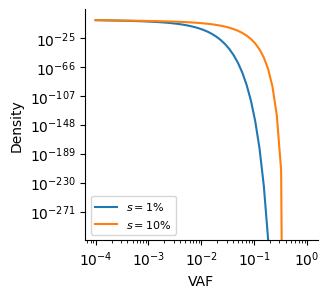

In [4]:
fig, ax = plt.subplots(1,1,figsize=(3,3))
afs = np.logspace(-4, 0)
neutral_watson = watson_pdf(t=60)
s1percent = watson_pdf(s=0.01, t=60)
s5percent = watson_pdf(s=0.05, t=60)
ax.loglog(afs, s1percent(afs)/np.nanmax(s1percent(afs)), label=r'$s=1\%$')
ax.loglog(afs, s5percent(afs)/np.nanmax(s1percent(afs)), label=r'$s=10\%$')
ax.legend(fontsize=8)
ax.set_ylabel('Density')
ax.set_xlabel('VAF')
debox(ax);
# ax.set_ylim(1e-4, 1e1)

In [5]:
def watson_loglik(ages, vafs, **kwargs):
    """Calculate the log-likelihood of Age vs. VAF observations."""
    loglik=np.zeros(ages.size)
    for i,(a,v) in enumerate(zip(ages,vafs)):
        # Density function for the variant frequency at age t
        loglik[i] = log_watson_pdf(t=a, **kwargs)(v)
    return np.sum(loglik)

def mle_s(ages, vafs, **kwargs):
    """
    Estimate selection effects under the Watson 2020 model.
    """
    assert np.all(ages) >= 0
    # assert np.all(vafs) > 0
    # assert np.all(vafs) < 0.5
    assert ages.size == vafs.size
    res = minimize_scalar(lambda x: -watson_loglik(ages, vafs, s=x), bounds=(1e-5,0.8))
    return res

def mle_mu_s(ages, vafs, **kwargs):
    """
    Estimate mutation and selection effects jointly under the Watson 2020 model.
    NOTE: this assumes N*tau ~ 10^5 approximately
    """
    assert np.all(ages) >= 0
    # assert np.all(vafs) > 0
    # assert np.all(vafs) < 0.5
    assert ages.size == vafs.size
    res = minimize(lambda x: -watson_loglik(ages, vafs, s=x[0], mu=x[1]), x0=[1e-4, 1.31e-9],
                   bounds=[(1e-5,0.8), (1e-10,5e-7)])
    return res

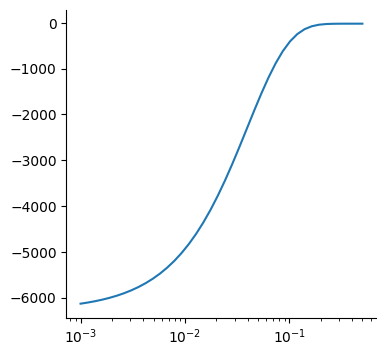

In [6]:
ages = np.array([38, 68, 36])
vafs = np.array([0.301, 0.279, 0.066])

fig, ax = plt.subplots(1,1,figsize=(4,4))
ss = np.logspace(-3, np.log10(0.5), 40)
logliks = [watson_loglik(ages, vafs, s=s) for s in ss]
ax.plot(ss, logliks)
ax.set_xscale('log')
debox(ax)

In [7]:
df = pl.read_excel('data/Table_TERTp_Age_VAF.xlsx')
df = df.with_columns(
    (
        pl.col('TERTp VAF') / 100
    ).alias('TERTp_VAF')
).rename({'Age at sequencing': 'Age'})
df.head()

Unique Pt ID,Age,TERTp Mutation?,TERTp VAF,TERTp_VAF
str,i64,str,f64,f64
"""523""",30,"""No""",0.0,0.0
"""531""",30,"""No""",0.0,0.0
"""392""",34,"""No""",0.0,0.0
"""526""",34,"""No""",0.0,0.0
"""539""",36,"""Yes""",30.3,0.303


499


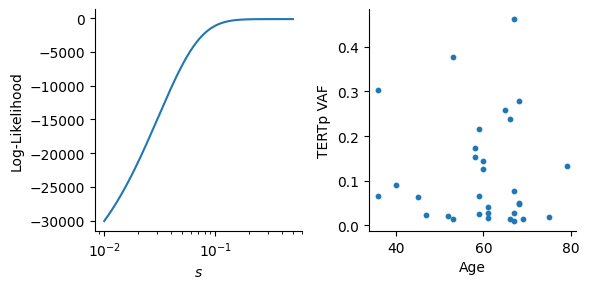

In [8]:
filt_df = df.filter((pl.col('TERTp_VAF') > 0) & (pl.col('TERTp_VAF') < 0.5))
ages = filt_df['Age'].to_numpy()
vafs = filt_df['TERTp_VAF'].to_numpy()
fig, [ax, ax1] = plt.subplots(1,2,figsize=(6,3), layout='tight')
ss = np.logspace(-2, np.log10(0.5), 500)
logliks = [watson_loglik(ages, vafs, s=s) for s in ss]
ax.plot(ss, logliks)
ax.set_xscale('log')
debox(ax);
ax.set_xlabel(r'$s$')
ax.set_ylabel('Log-Likelihood')
print(np.argmax(logliks))

ax1.scatter(ages, vafs, s=10)
ax1.set_xlabel('Age')
ax1.set_ylabel('TERTp VAF')
debox(ax1)

In [9]:
print(vafs)
mle_s(ages, vafs)

[0.303  0.066  0.09   0.0632 0.0236 0.0213 0.014  0.378  0.1736 0.154
 0.025  0.065  0.2164 0.145  0.127  0.027  0.016  0.042  0.259  0.238
 0.0145 0.028  0.462  0.077  0.0099 0.279  0.05   0.0485 0.014  0.02
 0.133 ]


 message: Solution found.
 success: True
  status: 0
     fun: 160.28288411552614
       x: 0.7999948307595903
     nit: 31
    nfev: 31

In [10]:
mle_mu_s(ages, vafs)

  message: CONVERGENCE: NORM OF PROJECTED GRADIENT <= PGTOL
  success: True
   status: 0
      fun: -23.999125681964543
        x: [ 8.000e-01  5.000e-07]
      nit: 1
      jac: [-1.421e-06 -6.263e+07]
     nfev: 6
     njev: 2
 hess_inv: <2x2 LbfgsInvHessProduct with dtype=float64>